
### 1. KONFIGURASI


In [1]:
import os
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, models, transforms
from torchvision.transforms import InterpolationMode
from skimage.feature import graycomatrix, graycoprops
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import random
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc


# Seed global untuk reproducibility
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f"Global Seed dikunci: {SEED}")

# Konfigurasi Dataset & Hyperparameter
DATA_DIR = r'C:\\Users\\taufi\\Documents\\Model - TA\\datasets\raw_bg_white_removed'
BATCH_SIZE     = 16
NUM_EPOCHS     = 30
LEARNING_RATE  = 2e-4
DEVICE         = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_MANUAL_FEAT = 196

print(f"Memulai Training di: {DEVICE}")

Global Seed dikunci: 42
Memulai Training di: cuda



### 2. EARLY STOPPING


In [2]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.0001):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = float('inf')
        self.stop = False

    def __call__(self, val_loss):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1
            print(f"⚠️ Early stopping counter: {self.counter}/{self.patience}")
            if self.counter >= self.patience:
                self.stop = True


### 3. EKSTRAKSI FITUR (WARNA & TEKSTUR)


In [3]:
def extract_color_features(image_np):
    hsv = cv2.cvtColor(image_np, cv2.COLOR_RGB2HSV)
    features = []
    for i in range(3):  
        hist = cv2.calcHist([hsv], [i], None, [64], [0, 256])
        features.extend(hist.flatten())
    return np.array(features, dtype=np.float32)

def extract_texture_features(image_np):
    gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)
    

    glcm = graycomatrix(gray, [1], [0], 256, symmetric=True, normed=True)
    contrast    = graycoprops(glcm, 'contrast')[0, 0]
    energy      = graycoprops(glcm, 'energy')[0, 0]
    homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
    correlation = graycoprops(glcm, 'correlation')[0, 0]

    return np.array([contrast, energy, homogeneity, correlation], dtype=np.float32)


### 4. CUSTOM DATASET


In [4]:
class AvocadoDataset(Dataset):
    def __init__(self, subset, base_transform=None, tensor_transform=None):
        self.subset = subset
        self.base_transform = base_transform
        self.tensor_transform = tensor_transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        image_pil, label = self.subset[idx]

        # Base Transform (Resize, Crop, Augmentasi)
        if self.base_transform:
            image_pil = self.base_transform(image_pil)
        
        # Ekstraksi fitur manual (untuk model hybrid)
        image_np = np.array(image_pil)
        color_feat   = extract_color_features(image_np)
        texture_feat = extract_texture_features(image_np)
        manual_feat  = np.concatenate([color_feat, texture_feat]) # 196 fitur

        # Tensor Transform (ToTensor & Normalisasi)
        if self.tensor_transform:
            image_tensor = self.tensor_transform(image_pil)
        else:
            image_tensor = transforms.ToTensor()(image_pil)
        
        return image_tensor, torch.tensor(manual_feat, dtype=torch.float32), label


### 5. TRANSFORM & STRATIFIED SPLIT (70-15-15)


In [5]:
# --- TRANSFORMASI TRAINING (AUGMENTASI AKTIF) ---
train_base_transform = transforms.Compose([
    transforms.Resize((256, 256), interpolation=InterpolationMode.BICUBIC),
    transforms.RandomResizedCrop(224, scale=(0.9, 1.0)), # Crop acak mencegah hafal background
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05)
])

# --- TRANSFORMASI VALIDASI & TEST (MURNI, TANPA AUGMENTASI) ---
val_base_transform = transforms.Compose([
    transforms.Resize((256, 256), interpolation=InterpolationMode.BILINEAR),
    transforms.CenterCrop(224)
])

# --- TENSOR TRANSFORM (SAMA UNTUK SEMUA) ---
tensor_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# --- LOAD DATASET SECARA OTOMATIS (TERPISAH ATAU GABUNGAN) ---
if os.path.exists(os.path.join(DATA_DIR, 'train')) and os.path.exists(os.path.join(DATA_DIR, 'val')) and os.path.exists(os.path.join(DATA_DIR, 'test')):
    print("✓ Mendeteksi struktur dataset terpisah (train/val/test)...")
    train_full_ds = datasets.ImageFolder(os.path.join(DATA_DIR, 'train'))
    val_full_ds   = datasets.ImageFolder(os.path.join(DATA_DIR, 'val'))
    test_full_ds  = datasets.ImageFolder(os.path.join(DATA_DIR, 'test'))
    
    class_names = train_full_ds.classes
    print(f"Kelas yang ditemukan: {class_names}")
    print(f"Distribusi Data: Train ({len(train_full_ds)}) | Val ({len(val_full_ds)}) | Test ({len(test_full_ds)})")
    
    train_dataset = AvocadoDataset(train_full_ds, base_transform=train_base_transform, tensor_transform=tensor_transform)
    val_dataset   = AvocadoDataset(val_full_ds,   base_transform=val_base_transform,   tensor_transform=tensor_transform)
    test_dataset  = AvocadoDataset(test_full_ds,  base_transform=val_base_transform,   tensor_transform=tensor_transform)
else:
    print("✓ Mendeteksi struktur dataset gabungan (melakukan stratified train_test_split)...")
    full_dataset = datasets.ImageFolder(DATA_DIR)
    class_names  = full_dataset.classes
    print(f"Kelas yang ditemukan: {class_names}")

    targets = full_dataset.targets
    indices = np.arange(len(targets))

    # Stratified Split
    train_idx, temp_idx = train_test_split(indices, test_size=0.30, stratify=targets, random_state=42)
    temp_targets = [targets[i] for i in temp_idx]
    val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=temp_targets, random_state=42)

    print(f"Distribusi Data: Train ({len(train_idx)}) | Val ({len(val_idx)}) | Test ({len(test_idx)})")

    train_subset = Subset(full_dataset, train_idx)
    val_subset   = Subset(full_dataset, val_idx)
    test_subset  = Subset(full_dataset, test_idx)

    train_dataset = AvocadoDataset(train_subset, base_transform=train_base_transform, tensor_transform=tensor_transform)
    val_dataset   = AvocadoDataset(val_subset,   base_transform=val_base_transform,   tensor_transform=tensor_transform)
    test_dataset  = AvocadoDataset(test_subset,  base_transform=val_base_transform,   tensor_transform=tensor_transform)

# --- DATALOADER (drop_last=True mencegah error BatchNorm saat batch sisa berukuran 1) ---
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, drop_last=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, drop_last=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, drop_last=False)


✓ Mendeteksi struktur dataset gabungan (melakukan stratified train_test_split)...
Kelas yang ditemukan: ['busuk', 'matang', 'mentah']
Distribusi Data: Train (189) | Val (40) | Test (41)



### 6. HYBRID MODEL (MOBILENETV3 + GLCM)


In [6]:
class HybridModel(nn.Module):
    def __init__(self, num_manual_features=196, num_classes=3):
        super().__init__()
        
        # Backbone MobileNetV3-Small - Dibekukan total agar tidak overfit
        backbone = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
        for param in backbone.parameters():
            param.requires_grad = False
            
        # Hapus classifier bawaan
        backbone.classifier = nn.Identity()
        self.backbone = backbone

        # Manual Branch (GLCM + Color)
        self.manual_branch = nn.Sequential(
            nn.BatchNorm1d(num_manual_features), 
            nn.Linear(num_manual_features, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU()
        )

        # Classifier Akhir (Kapasitas diturunkan ke 128 neuron)
        self.classifier = nn.Sequential(
            nn.Linear(576 + 64, 128), # Dari 256 menjadi 128
            nn.ReLU(),
            nn.Dropout(0.5),          # Dropout dinaikkan dari 0.4 ke 0.5
            nn.Linear(128, num_classes)
        )

    def forward(self, image, manual_feat):
        visual_out = self.backbone(image)
        manual_out = self.manual_branch(manual_feat)
        combined   = torch.cat([visual_out, manual_out], dim=1)
        return self.classifier(combined)


### 7. INISIALISASI


In [7]:
model = HybridModel(num_manual_features=NUM_MANUAL_FEAT, num_classes=len(class_names)).to(DEVICE)

# Gunakan Label Smoothing agar model tidak terlalu percaya diri pada data training
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

# Hanya optimasi layer classifier dan manual branch (backbone tetap freeze)
parameters_to_optimize = filter(lambda p: p.requires_grad, model.parameters())
optimizer = optim.AdamW(parameters_to_optimize, lr=LEARNING_RATE, weight_decay=1e-4)

# Scheduler yang menurunkan LR jika validation loss tidak turun
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=3)

scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == 'cuda')

C:\Users\taufi\AppData\Local\Temp\ipykernel_22388\203847777.py:13: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == 'cuda')



### 8. FUNGSI TRAINING & EVALUASI


In [8]:
def train_one_epoch(opt):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, manual_feats, labels in train_loader:
        images, manual_feats, labels = images.to(DEVICE), manual_feats.to(DEVICE), labels.to(DEVICE)
        opt.zero_grad()
        
        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == 'cuda'):
            outputs = model(images, manual_feats)
            loss    = criterion(outputs, labels)
            
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        
        running_loss += loss.item()
        _, preds = outputs.max(1)
        correct += preds.eq(labels).sum().item()
        total   += labels.size(0)
    return running_loss / len(train_loader), 100. * correct / total

def evaluate_loader(loader):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, manual_feats, labels in loader:
            images, manual_feats, labels = images.to(DEVICE), manual_feats.to(DEVICE), labels.to(DEVICE)
            
            with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == 'cuda'):
                outputs = model(images, manual_feats)
                loss    = criterion(outputs, labels)
                
            running_loss += loss.item()
            _, preds = outputs.max(1)
            correct += preds.eq(labels).sum().item()
            total   += labels.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    return running_loss / len(loader), 100. * correct / total, all_preds, all_labels


### 9. TRAINING LOOP


In [9]:
os.makedirs(r'C:\Users\taufi\Documents\Model - TA\output_model', exist_ok=True)

early_stopping = EarlyStopping(patience=10, min_delta=0.0001)
best_val_loss   = float('inf')
train_losses, val_losses, train_accs, val_accs = [], [], [], []

print("Memulai Training (Backbone tetap beku)...\n")

for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = train_one_epoch(optimizer)
    val_loss, val_acc, _, _ = evaluate_loader(val_loader)
    
    # Scheduler menggunakan Validation Loss
    scheduler.step(val_loss)
    
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    current_lr = optimizer.param_groups[0]['lr']
    print(f"Epoch {epoch+1:2d}/{NUM_EPOCHS} | LR: {current_lr:.6f} | "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc:.2f}% | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.2f}%")

    # Simpan model berdasarkan VALIDATION LOSS TERENDAH
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), r'C:\\Users\\taufi\\Documents\\Model - TA\\output_model\\best_model_no_lbp.pt')
        print(f"✅ Model terbaik disimpan! (Val Loss: {val_loss:.4f})")

    early_stopping(val_loss)
    if early_stopping.stop:
        print(f"⏹ Early stopping di epoch {epoch+1}!")
        break

Memulai Training (Backbone tetap beku)...

Epoch  1/30 | LR: 0.000200 | Train Loss: 1.0823 Acc: 43.18% | Val Loss: 1.0953 Acc: 25.00%
✅ Model terbaik disimpan! (Val Loss: 1.0953)
Epoch  2/30 | LR: 0.000200 | Train Loss: 1.0334 Acc: 56.82% | Val Loss: 1.0633 Acc: 34.38%
✅ Model terbaik disimpan! (Val Loss: 1.0633)
Epoch  3/30 | LR: 0.000200 | Train Loss: 1.0079 Acc: 62.50% | Val Loss: 1.0479 Acc: 43.75%
✅ Model terbaik disimpan! (Val Loss: 1.0479)
Epoch  4/30 | LR: 0.000200 | Train Loss: 0.9691 Acc: 69.32% | Val Loss: 1.0302 Acc: 43.75%
✅ Model terbaik disimpan! (Val Loss: 1.0302)
Epoch  5/30 | LR: 0.000200 | Train Loss: 0.9315 Acc: 69.32% | Val Loss: 1.0008 Acc: 43.75%
✅ Model terbaik disimpan! (Val Loss: 1.0008)
Epoch  6/30 | LR: 0.000200 | Train Loss: 0.8617 Acc: 77.84% | Val Loss: 0.9540 Acc: 53.12%
✅ Model terbaik disimpan! (Val Loss: 0.9540)
Epoch  7/30 | LR: 0.000200 | Train Loss: 0.8835 Acc: 66.48% | Val Loss: 0.8994 Acc: 56.25%
✅ Model terbaik disimpan! (Val Loss: 0.8994)
Epoch


### 10. EVALUASI AKHIR (TEST SET)



📊 Memuat ulang bobot model terbaik untuk pengujian (Test Set)...

📝 Classification Report pada DATA TEST (Acc Akhir: 95.12%):
              precision    recall  f1-score   support

       busuk       1.00      1.00      1.00        13
      matang       1.00      0.86      0.92        14
      mentah       0.88      1.00      0.93        14

    accuracy                           0.95        41
   macro avg       0.96      0.95      0.95        41
weighted avg       0.96      0.95      0.95        41



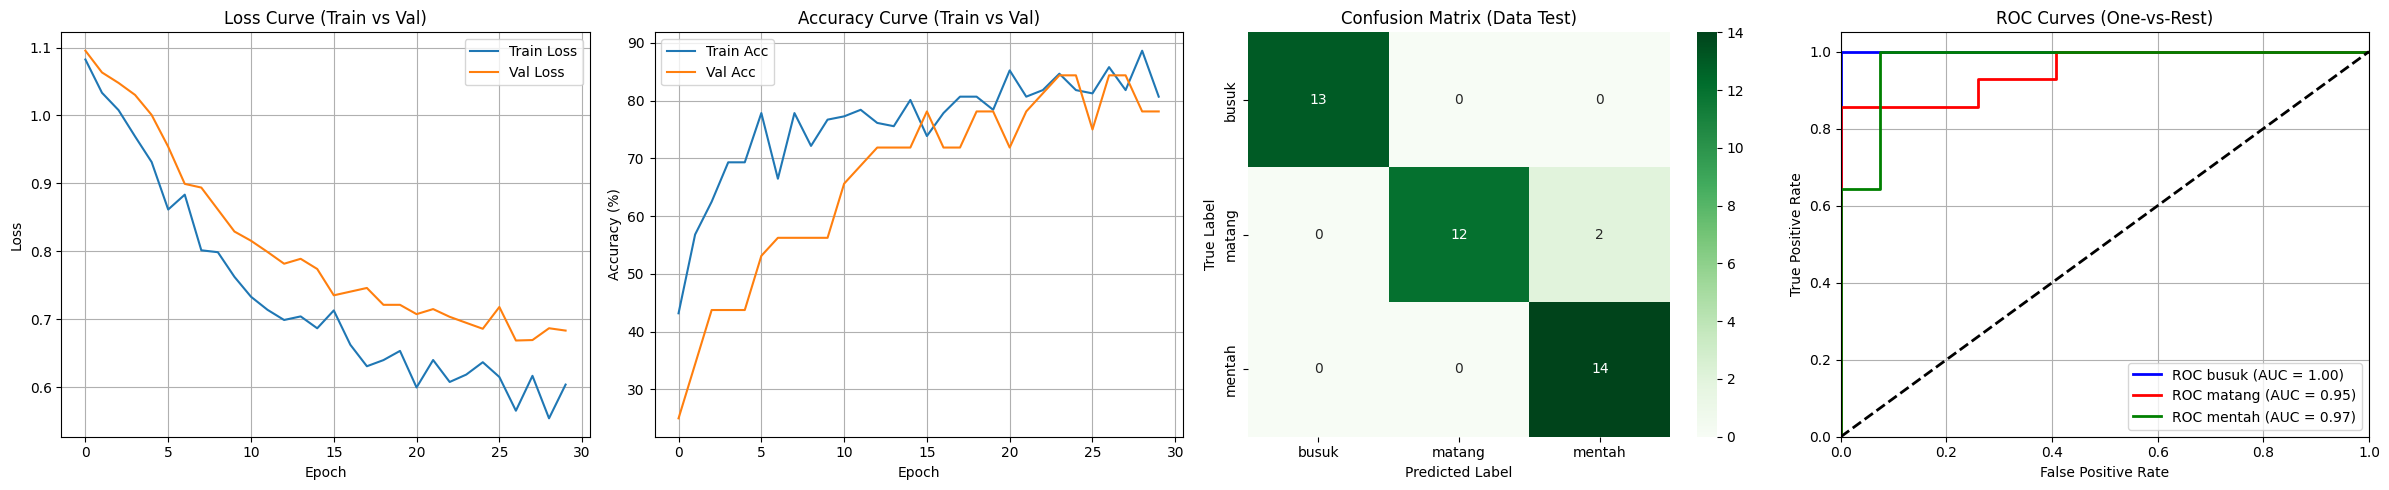


Pengujian Selesai! Skor Akurasi Murni pada Test Set: 95.12%


In [10]:
os.makedirs(r'C:\Users\taufi\Documents\Model - TA\output_grafik', exist_ok=True)
os.makedirs(r'C:\Users\taufi\Documents\Model - TA\output_model', exist_ok=True)

print("\n📊 Memuat ulang bobot model terbaik untuk pengujian (Test Set)...")
model.load_state_dict(torch.load(r'C:\\Users\\taufi\\Documents\\Model - TA\\output_model\\best_model_no_lbp.pt', weights_only=True))

test_loss, final_test_acc, test_preds, test_labels = evaluate_loader(test_loader)

print(f"\n📝 Classification Report pada DATA TEST (Acc Akhir: {final_test_acc:.2f}%):")
print(classification_report(test_labels, test_preds, target_names=class_names))

# ==================== HITUNG PROBABILITAS UNTUK ROC ====================
model.eval()
all_probs = []
all_labels_list = []
with torch.no_grad():
    for images, manual_feats, labels in test_loader:
        images, manual_feats = images.to(DEVICE), manual_feats.to(DEVICE)
        outputs = model(images, manual_feats)
        probs = torch.softmax(outputs, dim=1).cpu().numpy()
        all_probs.extend(probs)
        all_labels_list.extend(labels.cpu().numpy())

all_probs = np.array(all_probs)
all_labels_list = np.array(all_labels_list)

# Binarisasi label untuk One-vs-Rest
n_classes = len(class_names)
y_bin = label_binarize(all_labels_list, classes=range(n_classes))

fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_bin[:, i], all_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# ==================== PLOT 4 GRAFIK ====================
plt.figure(figsize=(24, 5))

# 1. Loss Curve
plt.subplot(1, 4, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses,   label='Val Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.title('Loss Curve (Train vs Val)')
plt.legend(); plt.grid(True)

# 2. Accuracy Curve
plt.subplot(1, 4, 2)
plt.plot(train_accs, label='Train Acc')
plt.plot(val_accs,   label='Val Acc')
plt.xlabel('Epoch'); plt.ylabel('Accuracy (%)')
plt.title('Accuracy Curve (Train vs Val)')
plt.legend(); plt.grid(True)

# 3. Confusion Matrix
plt.subplot(1, 4, 3)
cm = confusion_matrix(test_labels, test_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix (Data Test)')

# 4. ROC Curves (One-vs-Rest)
plt.subplot(1, 4, 4)
colors = ['blue', 'red', 'green']
for i, color in enumerate(colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'ROC {class_names[i]} (AUC = {roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves (One-vs-Rest)')
plt.legend(loc="lower right")
plt.grid(True)

plt.tight_layout()
plt.savefig(r'C:\\Users\\taufi\\Documents\\Model - TA\\output_grafik\\grafik_evaluasi_no_lbp.png')
plt.show()

print(f"\nPengujian Selesai! Skor Akurasi Murni pada Test Set: {final_test_acc:.2f}%")


### 11. VISUALISASI KURVA ROC STANDALONE (RESOLUSI TINGGI)


✅ Kurva ROC standalone beresolusi tinggi berhasil disimpan di: C:\Users\taufi\Documents\Model - TA\experiments\V3S_WBG\output_grafik\kurva_roc_standalone_V3S_WBG.png


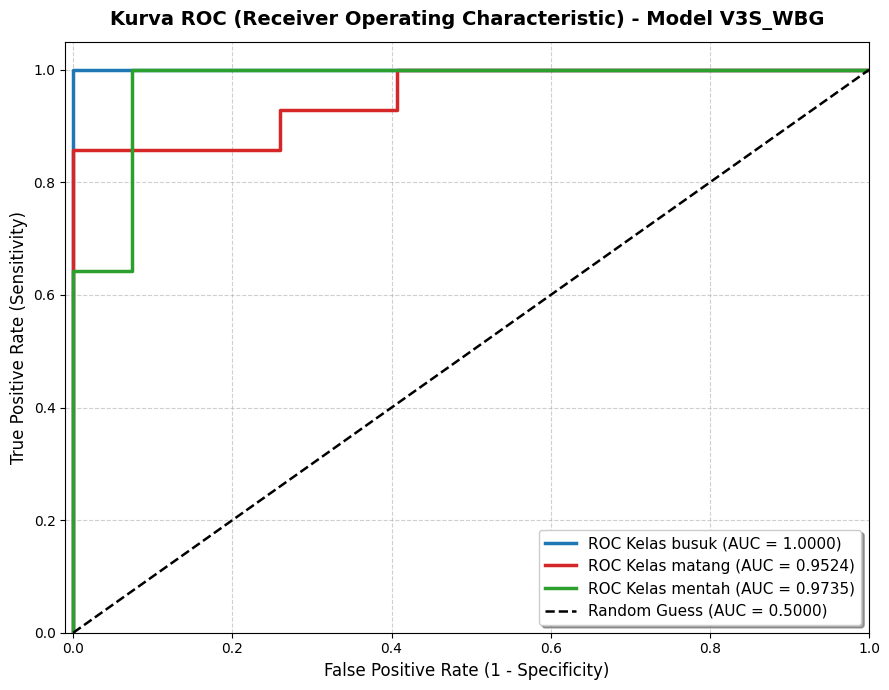

In [11]:
# ==================== PLOT KURVA ROC STANDALONE (RESOLUSI TINGGI) ====================
os.makedirs(r'C:\Users\taufi\Documents\Model - TA\experiments\V3S_WBG\output_grafik', exist_ok=True)

plt.figure(figsize=(9, 7))
colors = ['#1f77b4', '#d62728', '#2ca02c']
for i, color in enumerate(colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2.5,
             label=f'ROC Kelas {class_names[i]} (AUC = {roc_auc[i]:.4f})')

# Garis referensi tebakan acak (Random Guess)
plt.plot([0, 1], [0, 1], 'k--', lw=1.8, label='Random Guess (AUC = 0.5000)')

plt.xlim([-0.01, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('Kurva ROC (Receiver Operating Characteristic) - Model V3S_WBG', fontsize=14, fontweight='bold', pad=12)
plt.legend(loc="lower right", fontsize=11, frameon=True, shadow=True)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
roc_standalone_path = r'C:\Users\taufi\Documents\Model - TA\experiments\V3S_WBG\output_grafik\kurva_roc_standalone_V3S_WBG.png'
plt.savefig(roc_standalone_path, dpi=300)
plt.savefig(r'C:\Users\taufi\Documents\Model - TA\output_grafik\kurva_roc_standalone_V3S_WBG.png', dpi=300)
print(f"✅ Kurva ROC standalone beresolusi tinggi berhasil disimpan di: {roc_standalone_path}")
plt.show()